# Router and evaluation harness: walkthrough

This notebook goes through what is implemented in `router.py` (seen and unseen settings, `k` tuning, bootstrap interval, saved results) and the figures from `plots.py`.
It runs on the **synthetic data** from `test_router.py`: queries fall in clusters, each model is better on some clusters, and the observed score is a noisy 0/1 draw of the model's true quality.

| Piece | Function | Paper |
|---|---|---|
| kNN quality estimate | `knn_estimate` (sklearn `NearestNeighbors`) | Eq. 2 |
| Routing rule | `route` | Eq. 1 |
| λ sweep | `lambda_grid`, `curve` | §2 |
| Area under the cost-quality curve (log-cost axis) | `area` | §2 |
| Everything together | `evaluate(data, fit, new_model, n_probes, seed, k, tune_k)` | §7.2 |
| All figures | `plots.py` (one shared style) | §7.2 |

In [1]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

import plots  # every figure comes from here, in one style
from router import Results, area, evaluate, knn_estimate, knn_indices, lambda_grid, recovery, route
from test_router import make_data  # needs pytest installed (it is in .venv)

%matplotlib inline
# (importing test_router switched matplotlib to a non-interactive backend, hence the line above)

data, fit = make_data()
print(f"{len(data.queries)} queries, {len(data.models)} models, "
      f"{len(data.train)} train / {len(data.test)} test")
print("mean cost per query:", dict(zip(data.models, data.cost.round(2).tolist())))
print("mean observed score:", dict(zip(data.models, data.S.mean(0).round(2).tolist())))

4000 queries, 5 models, 2400 train / 1200 test
mean cost per query: {'model0': 1.0, 'model1': 2.11, 'model2': 4.47, 'model3': 9.46, 'model4': 20.0}
mean observed score: {'model0': 0.41, 'model1': 0.41, 'model2': 0.52, 'model3': 0.55, 'model4': 0.71}


## 1. The data and the `fit` interface

`Data` holds the queries, the observed scores `S` of shape `(queries, models)`, one **mean cost per model** (decided: the router cannot know the output length of a specific query), and the train/test indices.
It is a stand-in until Arman's schema is fixed.

`S` is one *observed* score per (query, model), a noisy sample of the true expected quality `q_m(x)`. The kNN average is what estimates `q`.

`fit(train_models)` returns the embedding function `embed(list[str]) -> ndarray`. This is how a learned embedding can be retrained without the held-out model. Here the embedding is frozen, so `fit` ignores its argument.

In [2]:
embed = fit(data.models)
E = embed(data.queries)
print("embedding matrix:", E.shape)
print("first scores (rows = queries, columns = models):")
print(data.S[:5])

embedding matrix: (4000, 8)
first scores (rows = queries, columns = models):
[[0. 0. 1. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]]


## 2. The kNN estimate `q̂_m(x)`

One embedding space, one estimate **per model**: the neighbors are the `k` nearest labeled queries (Euclidean distance), and each model averages **its own** scores over them.
Models labeled on the same queries share the neighbors, so `knn_estimate` takes a score matrix with one column per model and does a single neighbor search.

Toy example in one dimension, with two models:

In [3]:
E_lab = np.array([[0.], [1.], [10.]])           # three labeled queries
S_lab = np.array([[0., 1.], [1., 1.], [1., 0.]])  # scores of model A (column 0) and model B (column 1)
query = np.array([[0.4]])

print("neighbors of the query (k=2):", NearestNeighbors(n_neighbors=2).fit(E_lab).kneighbors(query, return_distance=False)[0])
print("q_hat for [model A, model B]:", knn_estimate(E_lab, S_lab, query, k=2)[0])

neighbors of the query (k=2): [0 1]
q_hat for [model A, model B]: [0.5 1. ]


The query's two nearest neighbors are labeled queries 0 and 1. Both models use these same neighbors but average different columns: A gets `(0 + 1)/2 = 0.5` and B gets `(1 + 1)/2 = 1.0`.

If `k` is larger than the number of labels (for example a new model with only a few probes), `knn_estimate` uses `min(k, n_labeled)`.

## 3. Routing and the cost weight λ

`route` picks, per query, the model with the highest `q̂ − λ·cost`. λ = 0 ignores cost; a large λ always picks the cheapest model. **Ties go to the cheaper model**, so the result does not depend on the order of the models.

Toy example with one query and three models of increasing quality and cost:

In [4]:
scores = np.array([[0.2, 0.5, 0.9]])
cost = np.array([1., 2., 10.])
for lam in [0, 0.03, 0.1, 0.5, 5]:
    print(f"λ = {lam:<5} -> model {route(scores, cost, lam)[0]}   (q̂ − λc = {(scores - lam * cost)[0].round(2)})")

λ = 0     -> model 2   (q̂ − λc = [0.2 0.5 0.9])
λ = 0.03  -> model 2   (q̂ − λc = [0.17 0.44 0.6 ])
λ = 0.1   -> model 1   (q̂ − λc = [ 0.1  0.3 -0.1])
λ = 0.5   -> model 0   (q̂ − λc = [-0.3 -0.5 -4.1])
λ = 5     -> model 0   (q̂ − λc = [ -4.8  -9.5 -49.1])


## 4. The λ sweep: cost-quality curves

`lambda_grid` builds `λ = 0` plus `n_lambdas = 500` log-spaced values (a design decision, a hyperparameter of `evaluate`), scaled by the cost range so `λ·(cost range)` spans `1e-3 … 1e3`.
For each λ, `realized` routes the test queries and returns the **realized** cost and quality of the chosen model for every query; `evaluate` averages them into the curves. Quality is the observed test score of the chosen model, since the true `q` is never available.

`evaluate` does this for three policies:
- **router**: routes by the kNN estimates `q̂`.
- **single best**: routes every query to one fixed model per λ, the one with the highest mean training quality minus `λ·cost`.
- **oracle**: routes by the observed test scores, which is the best any router could do.

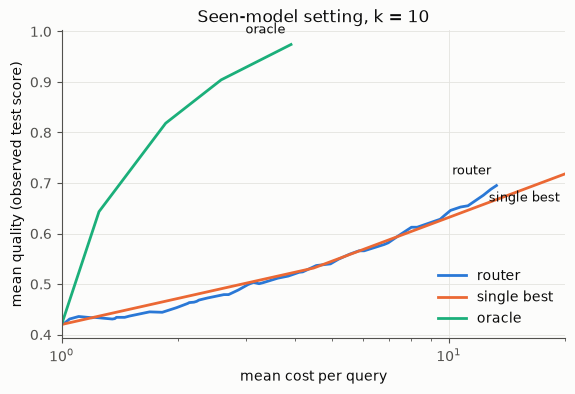

In [5]:
res = evaluate(data, fit, k=10)
fig = plots.plot_curves(res, "Seen-model setting, k = 10")

Each curve goes from the cheapest model (λ large, bottom left, where all three meet) to the best-quality routing (λ = 0, labeled end).
The x-axis is logarithmic and spans the full cost range of the pool, `[cheapest, most expensive]`, which is the range `A` is integrated over. Past its last point a curve is flat, since it cannot get better quality for more budget.

The oracle sees the realized, noisy outcomes, so it is not attainable. The single best is the bar to beat.

## 5. The area, the gain and `A`

`area` takes the curve, makes it monotone (best quality within a budget), interpolates linearly in cost between operating points, and integrates over `log(cost)` from the cheapest to the most expensive model, so every price decade weighs the same.

- **Main metric, the gain:** `area_router / area_single_best − 1`, a direct comparison with the single best.
- **Alongside, `gain_abs`:** the same difference in mean score averaged over the price range (log-cost), easier to interpret.
- **Secondary, `A`:** `area_router / area_oracle`, reported in parentheses.
- **Uncertainty:** `gain_ci`, a 95% paired bootstrap interval over the test queries (next section).

In [6]:
cost_range = (data.cost.min(), data.cost.max())
a = {name: area(c, *cost_range) for name, c in res["curves"].items()}
print({name: round(float(v), 3) for name, v in a.items()})
print(f"gain over single best: {a['router'] / a['single_best'] - 1:+.1%}   (evaluate says {res['gain']:+.1%})")
print(f"in mean score: {res['gain_abs']:+.3f} averaged over the price range")
print(f"(A = {res['A']:.3f} vs {res['A_single_best']:.3f} for the single best)")
lo, hi = res["gain_ci"]
print(f"95% bootstrap interval of the gain: [{lo:+.1%}, {hi:+.1%}]")

{'router': 1.643, 'single_best': 1.595, 'oracle': 2.667}
gain over single best: +3.0%   (evaluate says +3.0%)
in mean score: +0.016 averaged over the price range
(A = 0.616 vs 0.598 for the single best)
95% bootstrap interval of the gain: [-0.2%, +7.0%]


The interval comes from a **paired bootstrap over the test queries**. The router is not rerun: each test query's routed model and score are fixed.
We draw 1000 resamples of the test queries with replacement (the same resample for the router and the single best), recompute both areas and the gain on each, and take the 2.5th and 97.5th percentiles.
If the interval excludes 0, the router reliably beats the single best on this test set.

It only measures test-set sampling noise. Seeds (probe draws, and training seeds for learned embeddings) are repeated runs, and the train/test split is fixed (see the warnings in `decision.md`).

## 6. Choosing k

`evaluate(..., tune_k=True)` tunes `k` for the embedding it is given, on the **validation split only**, using the one-standard-error rule: the router's validation area is computed for each `k` in a grid, and the largest `k` within one bootstrap standard error of the best is chosen. `k` is tuned on the pool models only, so in the unseen setting the new model's labels are never used.

The validation split is reserved for this. Embedding training, early stopping included, must never see it.

In [7]:
grid = (1, 3, 5, 10, 20, 50, 100, 200, 300)
for kk in (10, 100):
    r = evaluate(data, fit, k=kk, n_boot=0)
    print(f"fixed k = {kk:<3}: gain {r['gain']:+.1%}   (A = {r['A']:.3f})")
r = evaluate(data, fit, tune_k=True, k_grid=grid)
lo, hi = r["gain_ci"]
print(f"tuned k = {r['k']:<3}: gain {r['gain']:+.1%}   95% interval [{lo:+.1%}, {hi:+.1%}]   (A = {r['A']:.3f})")

# the selected k next to up to three other values
by_k = {kk: evaluate(data, fit, k=kk, n_boot=0) for kk in sorted({r["k"], 3, 10, 50})}
for kk, x in by_k.items():
    print(f"k = {kk:<3}: gain {x['gain']:+.1%}   (A = {x['A']:.3f})")

fixed k = 10 : gain +3.0%   (A = 0.616)
fixed k = 100: gain +10.8%   (A = 0.663)


WARNING select_k: best k=300 is at the upper edge of the grid (1, 3, 5, 10, 20, 50, 100, 200, 300); the grid may be too narrow.


tuned k = 300: gain +11.3%   95% interval [+8.3%, +14.8%]   (A = 0.666)


k = 3  : gain -4.3%   (A = 0.572)
k = 10 : gain +3.0%   (A = 0.616)
k = 50 : gain +9.2%   (A = 0.653)
k = 300: gain +11.3%   (A = 0.666)


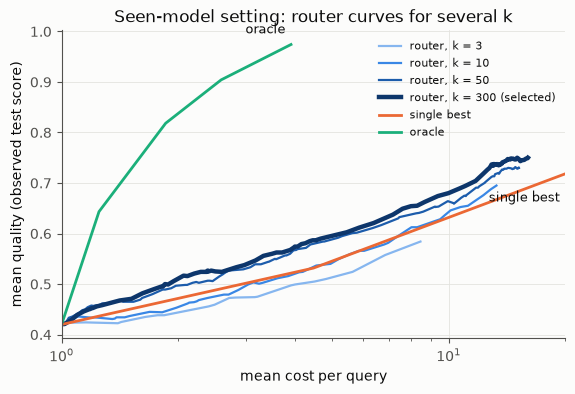

In [8]:
fig = plots.plot_curves_by_k(by_k, r["k"], "Seen-model setting: router curves for several k")

On this data larger `k` helps, because the 0/1 scores are noisy and averaging over more neighbors estimates the quality better; the chosen `k` is at the top of this grid. If the best `k` is at either edge of the grid, `select_k` prints a warning (as it does in the output above): the grid may be too narrow.
In the plot the router curves are shaded from light (small `k`) to dark (large `k`), and the selected `k` is the thick one. The single best and the oracle do not depend on `k`.
With `k = 3` the estimates are noisy and the router is **below** the single best (gain about -4%). The gain rises to about +3% at `k = 10`, +9% at `k = 50` and +11% at `k = 300`, so the improvement flattens as `k` grows.
The first plots and numbers above use the default `k = 10`; the unseen-model section below tunes `k`.

## 7. Unseen-model setting

Hold one model out. `evaluate(data, fit, new_model=..., n_probes=...)`:
- calls `fit(pool)` with the pool **without** the held-out model (a learned embedding retrains here),
- estimates the other models' quality from all training queries as before,
- estimates the new model's quality from **only its `n_probes` probe queries** (its own neighbor search),
- routes over all models, including the new one.

Three numbers are reported for an unseen run:
1. **`gain`** (main): over the **full-information single best**, which knows every model's quality, the new one included, from all training queries. This baseline is fixed: it does not change with `n_probes`.
2. **`gain_same_probes`**: over the single best that knows the new model only from the same `n` probes. More realistic for someone without a router, but noisier.
3. **`recovery`**: the unseen gain divided by the seen-model gain, both over the same fixed baseline: the fraction of what the router achieves with full information that `n` probes recover.

`k` is tuned for each run on the pool without `model2` (`tune_k=True`). Means over 5 seeds (each seed is one nested family of probe sets, drawn from the training queries inside `evaluate`); the band is min to max.

k tuned on the pool without model2: {300}
seen-model gain (tuned k): +11.3%

 probes |     gain | same probes | recovery
      1 |    +0.4% |       +6.9% |       3%
      2 |    +0.2% |       +4.3% |       2%
      5 |    +4.8% |       +7.4% |      42%
     10 |    +6.5% |       +7.7% |      57%
     20 |    +7.9% |      +11.6% |      70%
     50 |    +7.9% |       +7.9% |      70%
    100 |    +8.2% |       +8.2% |      72%
    500 |    +8.6% |       +8.6% |      76%
   2400 |   +11.3% |      +11.3% |     100%


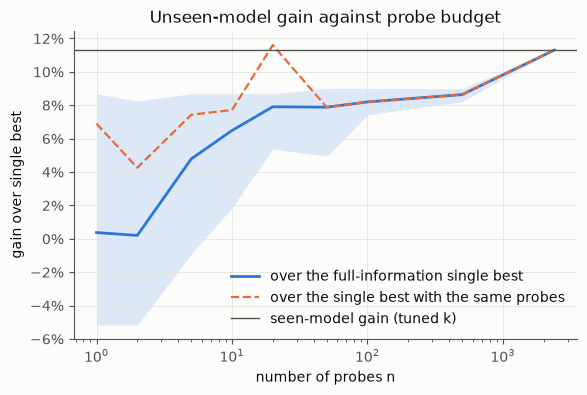

In [9]:
n_grid = [1, 2, 5, 10, 20, 50, 100, 500, len(data.train)]
unseen = [[evaluate(data, fit, new_model="model2", n_probes=n, seed=s, tune_k=True, k_grid=(10, 100, 300, 1000),
                    n_boot=0) for s in range(5)] for n in n_grid]
gain = np.array([[x["gain"] for x in row] for row in unseen])
gain_same_probes = np.array([[x["gain_same_probes"] for x in row] for row in unseen])
rec = np.array([[recovery(x, r) for x in row] for row in unseen])

print("k tuned on the pool without model2:", {x["k"] for row in unseen for x in row})
print(f"seen-model gain (tuned k): {r['gain']:+.1%}\n")
print(f"{'probes':>7} | {'gain':>8} | {'same probes':>11} | {'recovery':>8}")
for n, g, gs, rc in zip(n_grid, gain.mean(1), gain_same_probes.mean(1), rec.mean(1)):
    print(f"{n:>7} | {g:>+8.1%} | {gs:>+11.1%} | {rc:>8.0%}")

fig = plots.plot_gain_vs_probes(n_grid, gain, r["gain"], gain_same_probes)

With the fixed baseline the gain rises with the probe budget: about 0% on average with 1 or 2 probes (some probe draws fall below the baseline, see the band), about +5% with 5, about +8% from 20 probes on, and the seen-model gain (+11%) when all training queries are probes. The recovery goes from a few percent with 1 or 2 probes to about 70% at 20 probes, 76% at 500, and 100% at the end. Probe sets are nested across budgets for a given seed (the 5 probes are the start of the 10), which keeps the curve smooth. Five probe draws per point: read the trend, not single points.
The gain over the single best that only has the same probes is larger at small `n`, because that baseline is weaker there (it often picks the wrong model); the two coincide once `n` is large. This is why the fixed full-information baseline is the main one.
Even with 500 probes the recovery stays below 100%: the new model's estimate then averages over sparser neighbors than the models labeled on all 2400 training queries.

## 8. Saving the results

`Results` writes every run into a new timestamped folder (gitignored) so the outputs can be reused later: `results.csv` with one row per run, one `.npz` per run with the curves and the test `q̂`, the split indices, and `meta.json` (time, git commit, models, costs).
Because `q̂` is saved, the routing, area and gain can be recomputed without refitting an embedding or rerunning the kNN, which matters while parts of the area definition are provisional.
Here the folder is a temporary directory; in a real experiment use `Results(data, "llmrouterbench")`, which writes under `./results/`.

In [10]:
import csv, tempfile
from pathlib import Path

out = Results(data, "synthetic", root=tempfile.mkdtemp())
kw = dict(tune_k=True, k_grid=(10, 100, 300, 1000), n_boot=200)
out.run("frozen", fit, **kw)
out.run("frozen", fit, new_model="model2", n_probes=50, seed=0, **kw)

print(out.dir.name)
for p in sorted(out.dir.rglob("*")):
    print("  ", p.relative_to(out.dir))
print()
for row in csv.DictReader(open(out.dir / "results.csv")):
    print({key: (f"{float(v):.3f}" if key.startswith(("gain", "A")) and v else v) for key, v in row.items()})

2026-11-08_14-03-38_split0
   meta.json
   results.csv
   runs
   runs/0000.npz
   runs/0001.npz
   split.npz

{'run': '0000', 'benchmark': 'synthetic', 'embedding': 'frozen', 'new_model': '', 'n_probes': '', 'seed': '0', 'split_seed': '0', 'tune_k': 'True', 'k': '300', 'n_lambdas': '500', 'gain': '0.113', 'gain_abs': '0.060', 'gain_same_probes': '', 'recovery': '', 'gain_ci_low': '0.078', 'gain_ci_high': '0.144', 'A': '0.666', 'A_single_best': '0.598'}
{'run': '0001', 'benchmark': 'synthetic', 'embedding': 'frozen', 'new_model': 'model2', 'n_probes': '50', 'seed': '0', 'split_seed': '0', 'tune_k': 'True', 'k': '300', 'n_lambdas': '500', 'gain': '0.087', 'gain_abs': '0.046', 'gain_same_probes': '0.087', 'recovery': '0.7654042876404087', 'gain_ci_low': '0.054', 'gain_ci_high': '0.123', 'A': '0.650', 'A_single_best': '0.598'}


## 9. What the embedding space looks like (PCA)

`plots.pca_project` projects the embeddings on the first two principal axes, **fitted on the training queries**. The axis labels give the share of variance each axis holds. PCA is linear and keeps only two directions, so the neighbors the kNN finds in the full space can look far apart here (the neighbor plot at the end shows this).

Categorical colors in a scatter are limited to three, so the group plots are **small multiples**: one panel per group, the group in blue over all points in gray.

PC1 and PC2 hold 63% of the variance of the 8-dimensional embedding


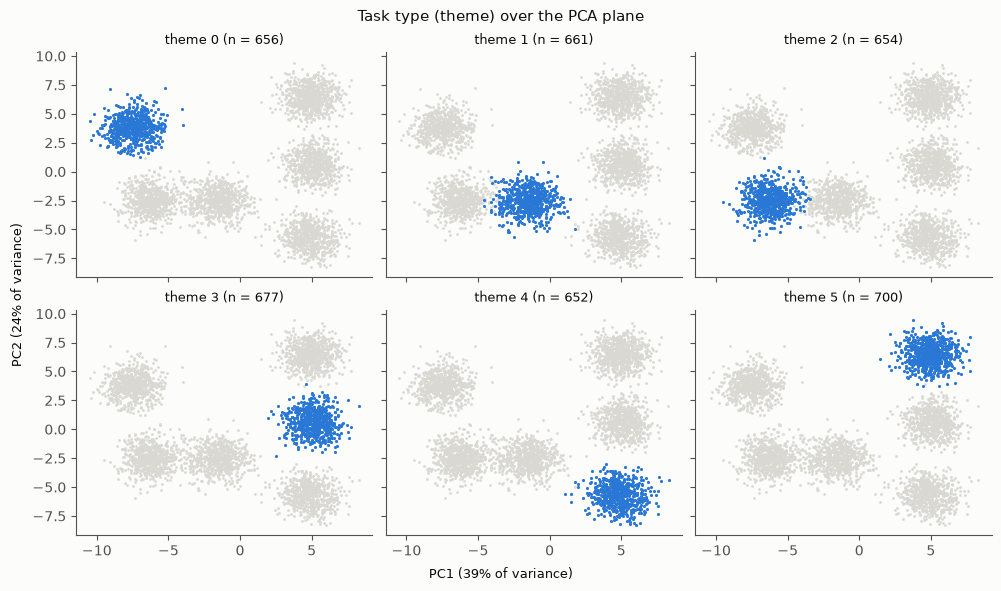

In [11]:
E = fit(data.models)(data.queries)
Z, ratio = plots.pca_project(E, fit_idx=data.train)
print(f"PC1 and PC2 hold {ratio.sum():.0%} of the variance of the {E.shape[1]}-dimensional embedding")

themes = {t: f"theme {t}" for t in np.unique(data.theme)}
fig = plots.plot_pca_groups(Z, ratio, data.theme, "Task type (theme) over the PCA plane", names=themes)

The six themes form six well-separated clusters. This is by construction in the synthetic data; real embeddings will overlap more, and how much task type alone captures is what RQ1a asks.

**What each model does.** One panel per model: the observed score averaged in hexagonal bins of the plane, on a shared 0-1 scale. If neighboring bins have similar colors, a kNN average over neighbors has something to work with.

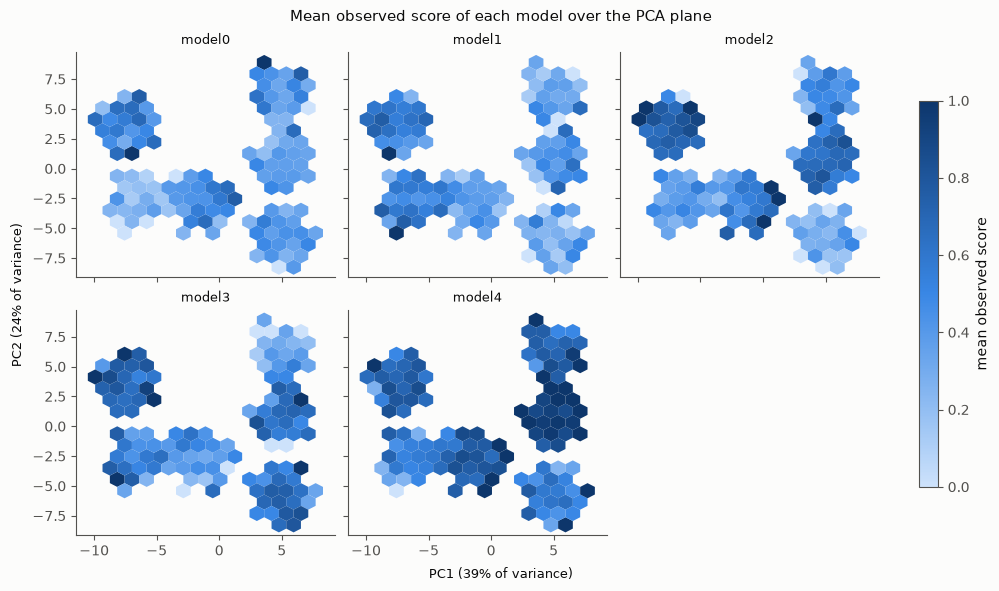

In [12]:
fig = plots.plot_pca_quality(Z[data.train], ratio, data.S[data.train], data.models)

A model's score is roughly constant within a cluster, and the pattern across clusters differs from model to model: which model is best depends on where the query sits. This is the structure the kNN average exploits.

**Routing map.** The model the router (tuned `k`) sends each test query to, at one λ. Here `λ · (cost range) = 0.1`. The panels follow the order of the models, models that are never chosen included.

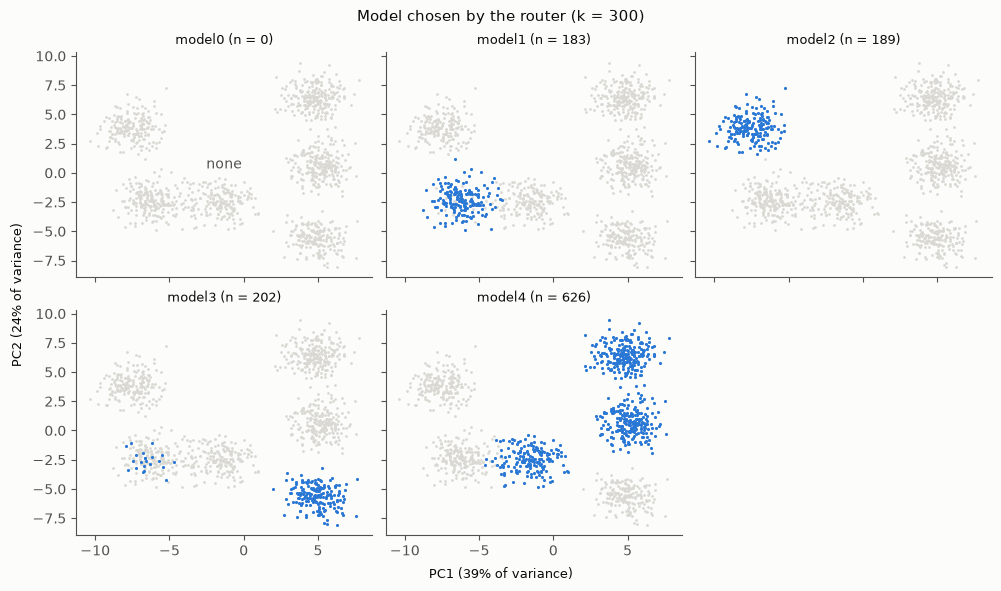

In [13]:
lam = 0.1 / np.ptp(data.cost)
picks = route(r["Q_hat"], data.cost, lam)
fig = plots.plot_pca_groups(Z[data.test], ratio, picks, f"Model chosen by the router (k = {r['k']})",
                            names=dict(enumerate(data.models)), groups=range(len(data.models)))

Almost every cluster is sent to a single model, and different clusters go to different models. `model0` is never chosen at this λ, so its panel is empty. A single best model would send every query to the same model.

**Variance explained.** How many components hold the variance of the embedding. The extra lines are an illustration with a made-up query length: appended raw (in tokens) it dominates the Euclidean distance, appended standardized it does not. This is why the handcrafted features are standardized, and why each embedding owns its scaling.

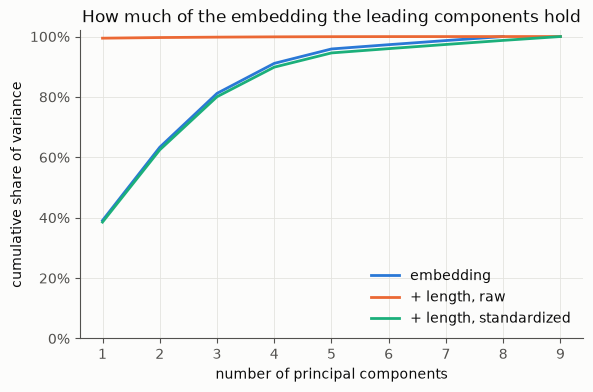

In [14]:
length = np.random.default_rng(0).lognormal(5, 0.6, len(E))  # made-up query length in tokens
raw = np.c_[E, length]
standardized = np.c_[E, (length - length.mean()) / length.std()]
fig = plots.plot_explained_variance({"embedding": E, "+ length, raw": raw, "+ length, standardized": standardized},
                                    fit_idx=data.train, max_components=9)

The embedding alone needs about 5 components for 95% of its variance. With a raw length in tokens appended, about 99% of the variance sits in the first component: that one feature would dominate every Euclidean distance. Standardized, it changes nothing visible (the green line lies on top of the blue one).

**Probes (unseen-model setting).** The 50 probes of the held-out `model2` over the training queries, and the test queries the router sends to `model2`.

198 of 1200 test queries are routed to model2 at this λ


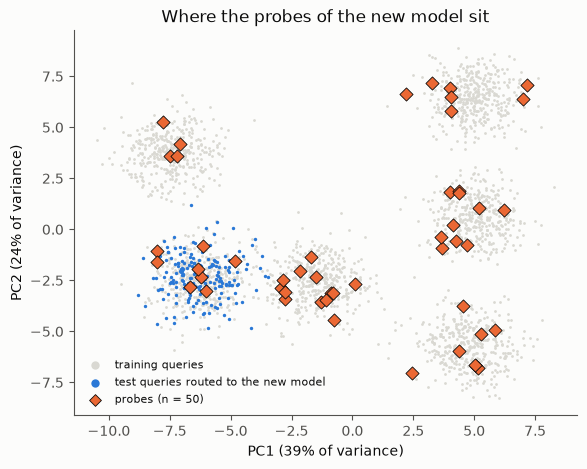

In [15]:
unseen = evaluate(data, fit, new_model="model2", n_probes=50, seed=0, tune_k=True, k_grid=(10, 100, 300, 1000), n_boot=0)
new = data.models.index("model2")
routed = data.test[route(unseen["Q_hat"], data.cost, lam) == new]
print(f"{len(routed)} of {len(data.test)} test queries are routed to model2 at this λ")
fig = plots.plot_probes(Z, ratio, data.train, unseen["probes"], routed)

The 50 probes reach every cluster but sparsely, a handful per cluster. The test queries routed to `model2` (blue) fall in one cluster, which is where `model2` is the best choice at this λ.

**One query and its neighbors.** A test query (star) and the labeled queries its quality estimates are averaged over. The pool models use its `k` nearest **training** queries (blue). The new model, which only has its probes, uses the `k` nearest **probes** (orange diamonds).
`k = 20` here so the neighbors stay readable; the tuned `k` would highlight a large part of a cluster.

model0: q̂ = 0.65, observed score of this query = 0
model1: q̂ = 0.30, observed score of this query = 0
model2: q̂ = 0.40, observed score of this query = 1   (from its probes only: 0.70)
model3: q̂ = 0.15, observed score of this query = 1
model4: q̂ = 0.85, observed score of this query = 1


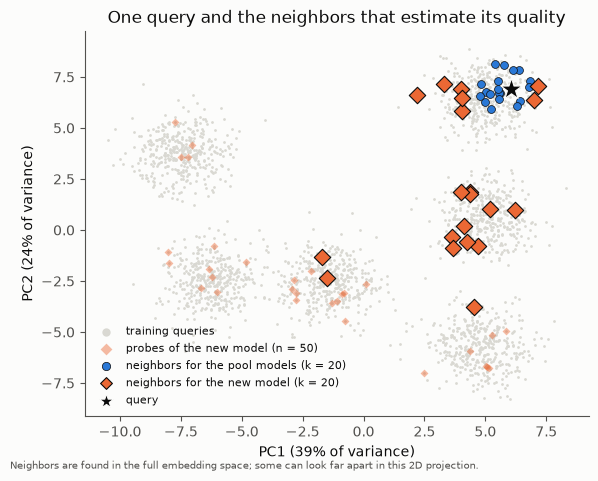

In [16]:
q, k = data.test[0], 20
tr, probes = data.train, unseen["probes"]
neighbors = tr[knn_indices(E[tr], E[[q]], k)[0]]            # shared by the pool models
probe_neighbors = probes[knn_indices(E[probes], E[[q]], k)[0]]  # the new model only has its probes

q_pool = knn_estimate(E[tr], data.S[tr], E[[q]], k)[0]
q_new = knn_estimate(E[probes], data.S[probes][:, [new]], E[[q]], k)[0, 0]
for m, name in enumerate(data.models):
    extra = f"   (from its probes only: {q_new:.2f})" if m == new else ""
    print(f"{name}: q̂ = {q_pool[m]:.2f}, observed score of this query = {data.S[q, m]:.0f}{extra}")

fig = plots.plot_neighbors(Z, ratio, tr, q, neighbors, probes, probe_neighbors)

The pool models' 20 neighbors (blue) sit right next to the query, in its own cluster. The new model has only 50 probes, and filling `k = 20` takes 20 of them, so its neighbors (orange diamonds) spread over several clusters: its estimate averages queries that are not like this one. For `model2` the estimate is 0.40 from all training labels and 0.70 from its probes only (the observed score of this query is 1). This is the cost of a small probe budget, and it is why `k` is capped at the number of probes.

## Status

**Done (phase 1):** kNN estimator, routing, λ sweep, single-best baseline, oracle, area `A`, the gain with its bootstrap interval, `k` tuning on the validation split, saving of results, `evaluate` for the seen and unseen settings, the shared `plots.py` (cost-quality curves, PCA views, probes, neighbors), and tests on synthetic data (`test_router.py`).

**Decided:** the area definition (log-cost axis, pool cost range, ties to the cheaper model, 500 λ values, monotone envelope, observed-score oracle, gains compared within an epoch) and the unseen-setting reporting (gain over the full-information single best, gain over the same-probes single best, recovery). See `decision.md`.

**Still open:**
- The mean cost per model and the `Data` format depend on Arman's schema.

**Next:** nothing required. Optional: probes-to-target (now simple: the smallest `n` whose recovery reaches a target) and sensitivity checks on λ (including `n_lambdas`) and `k`.